# Zhang et al. (ICLR 2017), Figure 1: reproduction

All training and plotting code (`phase1.py`, `phase3.py`) was written by **Claude Sonnet 5.5 (Medium effort) in the claude.ai
chat interface**; the full conversation is in `llm_transcript.md`. This notebook only calls those scripts and shows their outputs.

Pipeline
1. Panels (b), (c) for MLP 1x512 and AlexNet: `phase1.py train --grid reduced` (25k steps, batch 128, p in {0, 0.1, ..., 1}).
2. Inception (panels a, b, c): `phase3.py train --grid reduced --archs inception` (p in {0, 0.2, ..., 1} plus the three input corruptions).
3. Figure: `phase3.py plot` with the accuracy-based convergence criterion (train acc >= 0.98) for panel (b).

CIFAR-10 is loaded with torchvision. If you downloaded it from the official site, you can run the scripts directly. We used the Hugging Face
mirror (`../tools/cifar_from_parquet.py`), whose pickles fail torchvision's md5 check, hence `../tools/run_patched.py`, which disables only that check and the download.

In [1]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, display

HERE = Path.cwd()                      # run this notebook from its own folder
PY = sys.executable
RUN_TRAINING = False                   # True = retrain from scratch (hours on a laptop GPU)

def run(*args):
    """Run one of the LLM-generated scripts and stream its output."""
    cmd = [PY, *map(str, args)]
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=HERE, check=True)

def show_csv(path):
    import csv
    rows = list(csv.reader(open(path)))
    w = [max(len(r[i]) for r in rows) for i in range(len(rows[0]))]
    for r in rows:
        print("  ".join(c.ljust(n) for c, n in zip(r, w)))

## 1. Training (skipped by default; the logs are in `phase1_runs/` and `phase3_runs/`)

In [2]:
if RUN_TRAINING:
    run("../tools/run_patched.py", "phase1.py", "train", "--grid", "reduced", "--archs", "mlp1x512", "alexnet",
        "--out", "phase1_runs", "--data_root", "../data")
    run("../tools/run_patched.py", "phase3.py", "train", "--grid", "reduced", "--archs", "inception",
        "--out", "phase3_runs", "--data_root", "../data")
    # the final figure reads all runs from phase3_runs/runs; MLP and AlexNet come from phase1_runs
    for d in (HERE / "phase1_runs/runs").iterdir():
        link = HERE / "phase3_runs/runs" / d.name
        if not link.exists():
            link.symlink_to(Path("../../phase1_runs/runs") / d.name)

## 2. Figure 1 from the saved logs

In [3]:
run("phase3.py", "plot", "--out", "phase3_runs", "--criterion", "acc", "--acc_threshold", "0.98",
    "--acc_thresholds", "0.95", "0.98", "0.99", "--taus", "0.02", "0.05", "0.1")

$ /Volumes/Projects/CS_6362-Advanced_Machine_Learning/assignment2/.venv/bin/python phase3.py plot --out phase3_runs --criterion acc --acc_threshold 0.98 --acc_thresholds 0.95 0.98 0.99 --taus 0.02 0.05 0.1


{'arch': 'inception', 'p': 0.0, 'steps_run': 25000, 'cross_step': 4100, 'rel_time': 1.0, 'censored_b': False, 'test_err': 0.1685, 'train_err': 0.02502, 'converged_c': True, 'criterion': 'acc', 'threshold': 0.98, 'early_stopped_log': False}
{'arch': 'inception', 'p': 0.2, 'steps_run': 8300, 'cross_step': 7200, 'rel_time': 1.7560975609756098, 'censored_b': False, 'test_err': 0.3331, 'train_err': 0.01888, 'converged_c': True, 'criterion': 'acc', 'threshold': 0.98, 'early_stopped_log': True}
{'arch': 'inception', 'p': 0.4, 'steps_run': 10200, 'cross_step': 9100, 'rel_time': 2.2195121951219514, 'censored_b': False, 'test_err': 0.4613, 'train_err': 0.0041, 'converged_c': True, 'criterion': 'acc', 'threshold': 0.98, 'early_stopped_log': True}
{'arch': 'inception', 'p': 0.6, 'steps_run': 11700, 'cross_step': 10600, 'rel_time': 2.5853658536585367, 'censored_b': False, 'test_err': 0.648, 'train_err': 0.00548, 'converged_c': True, 'criterion': 'acc', 'threshold': 0.98, 'early_stopped_log': True}


### Reproduction (top) vs. original (bottom)

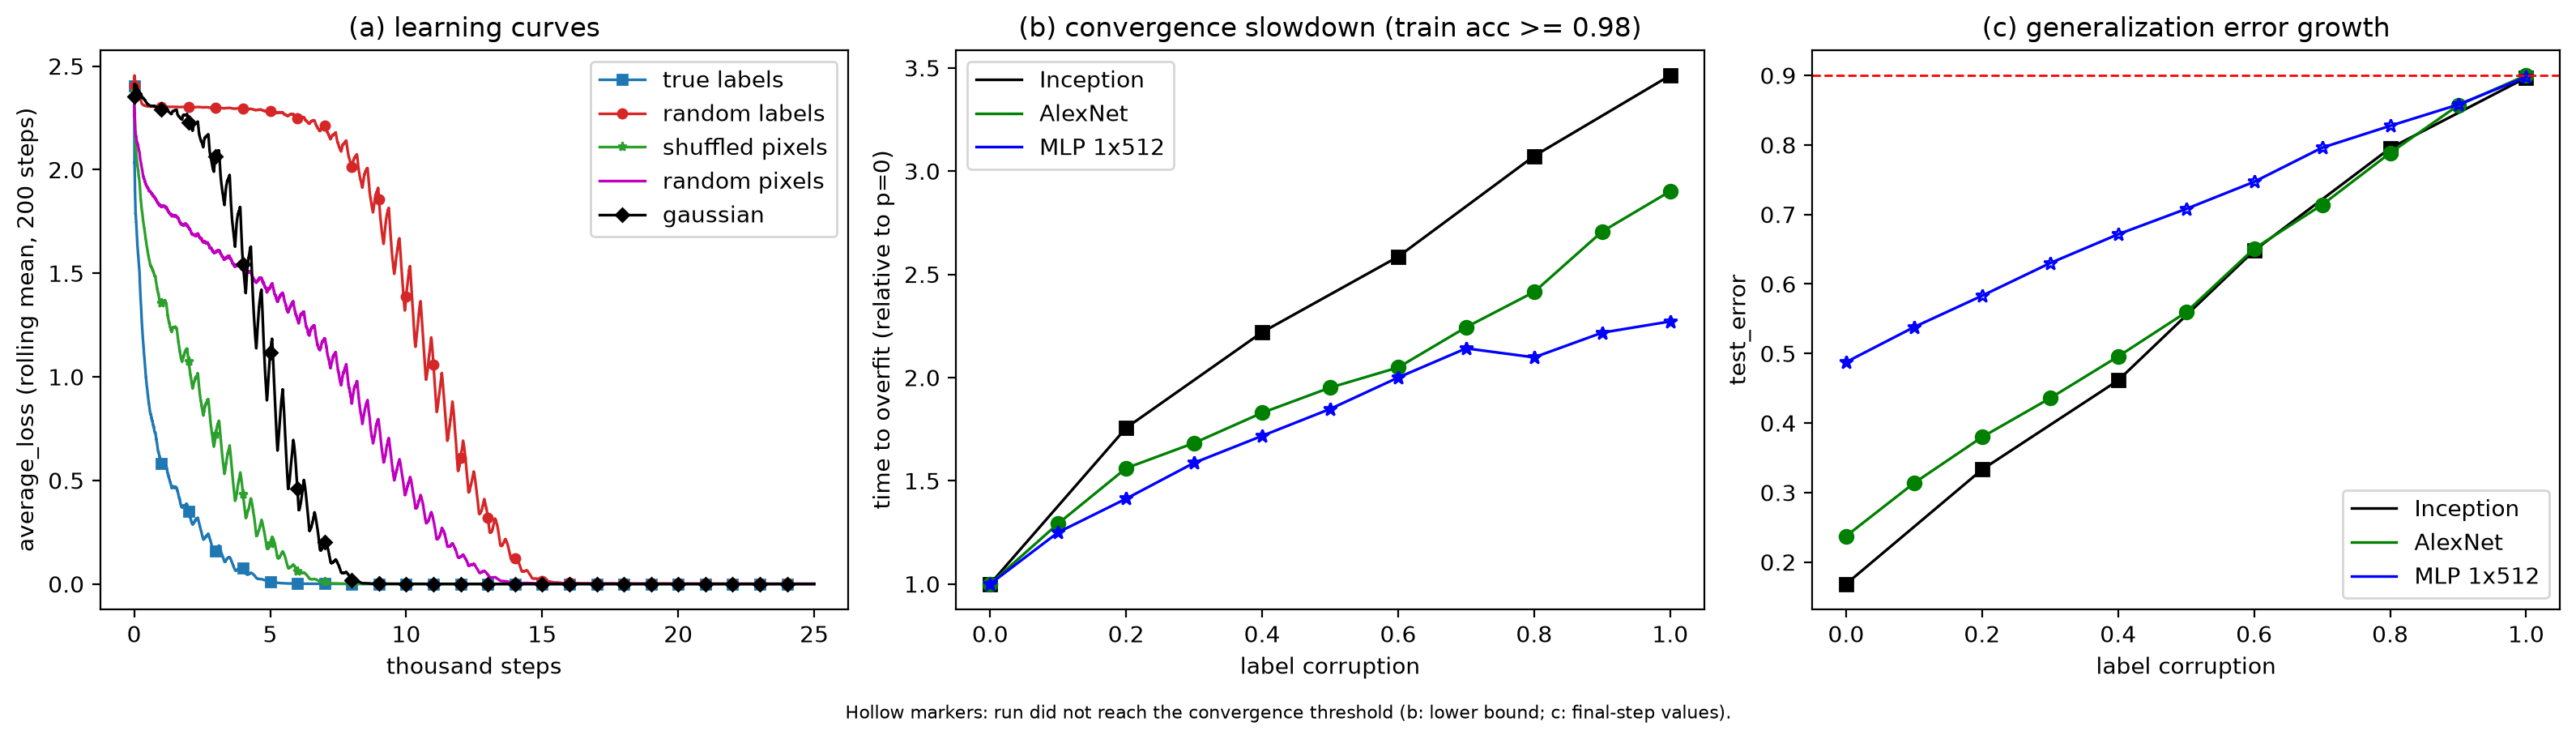

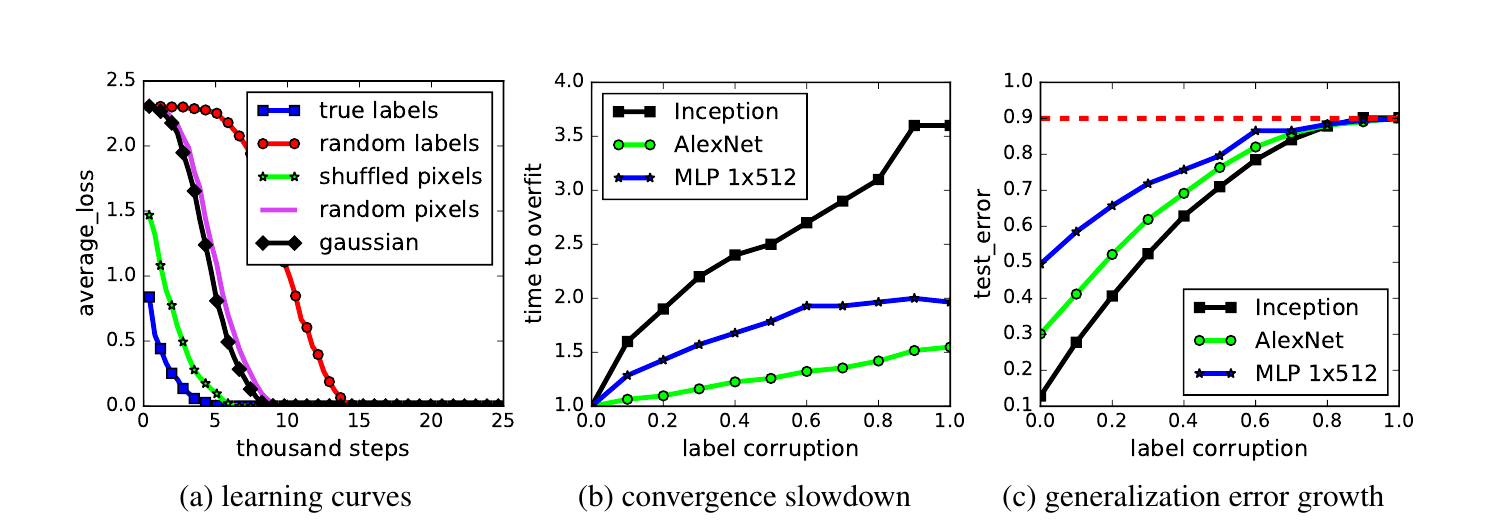

In [4]:
display(Image("phase3_runs/figure1.png"))
display(Image("original_figure1.png"))

### Panel (b) under other convergence criteria (sensitivity check)

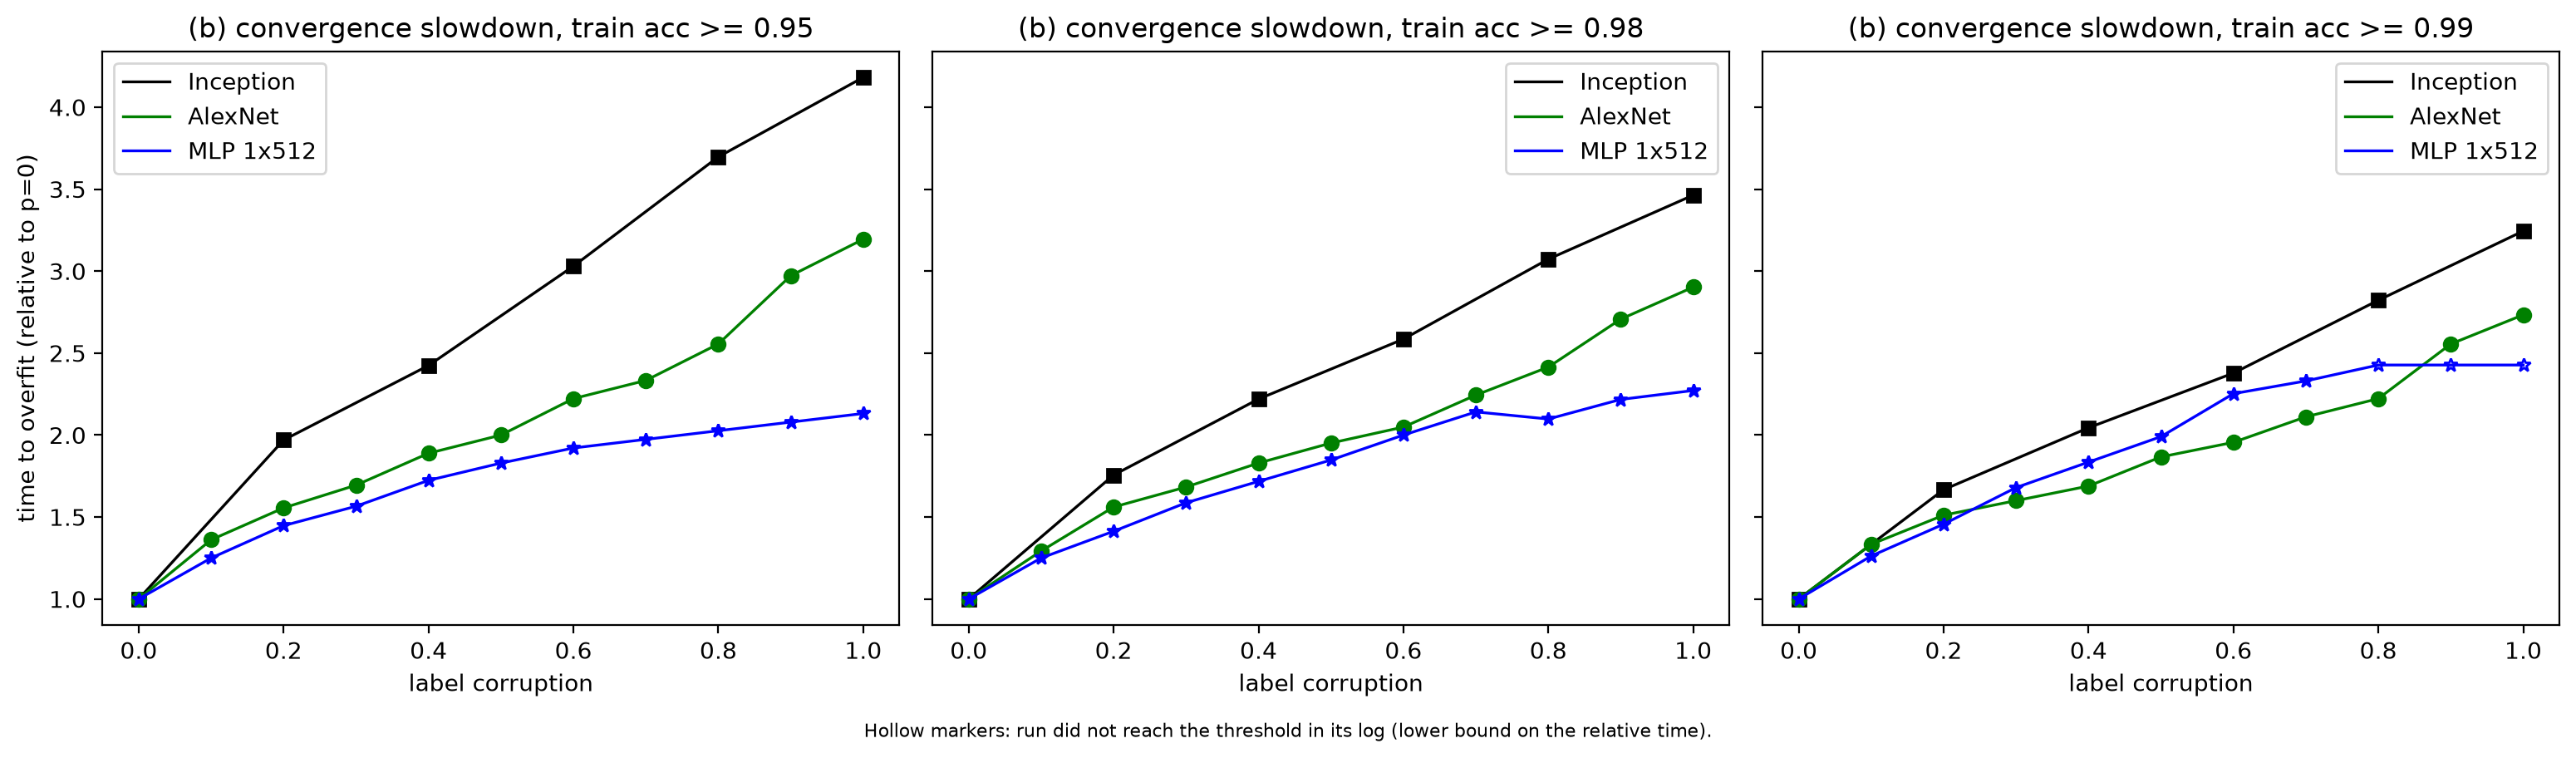

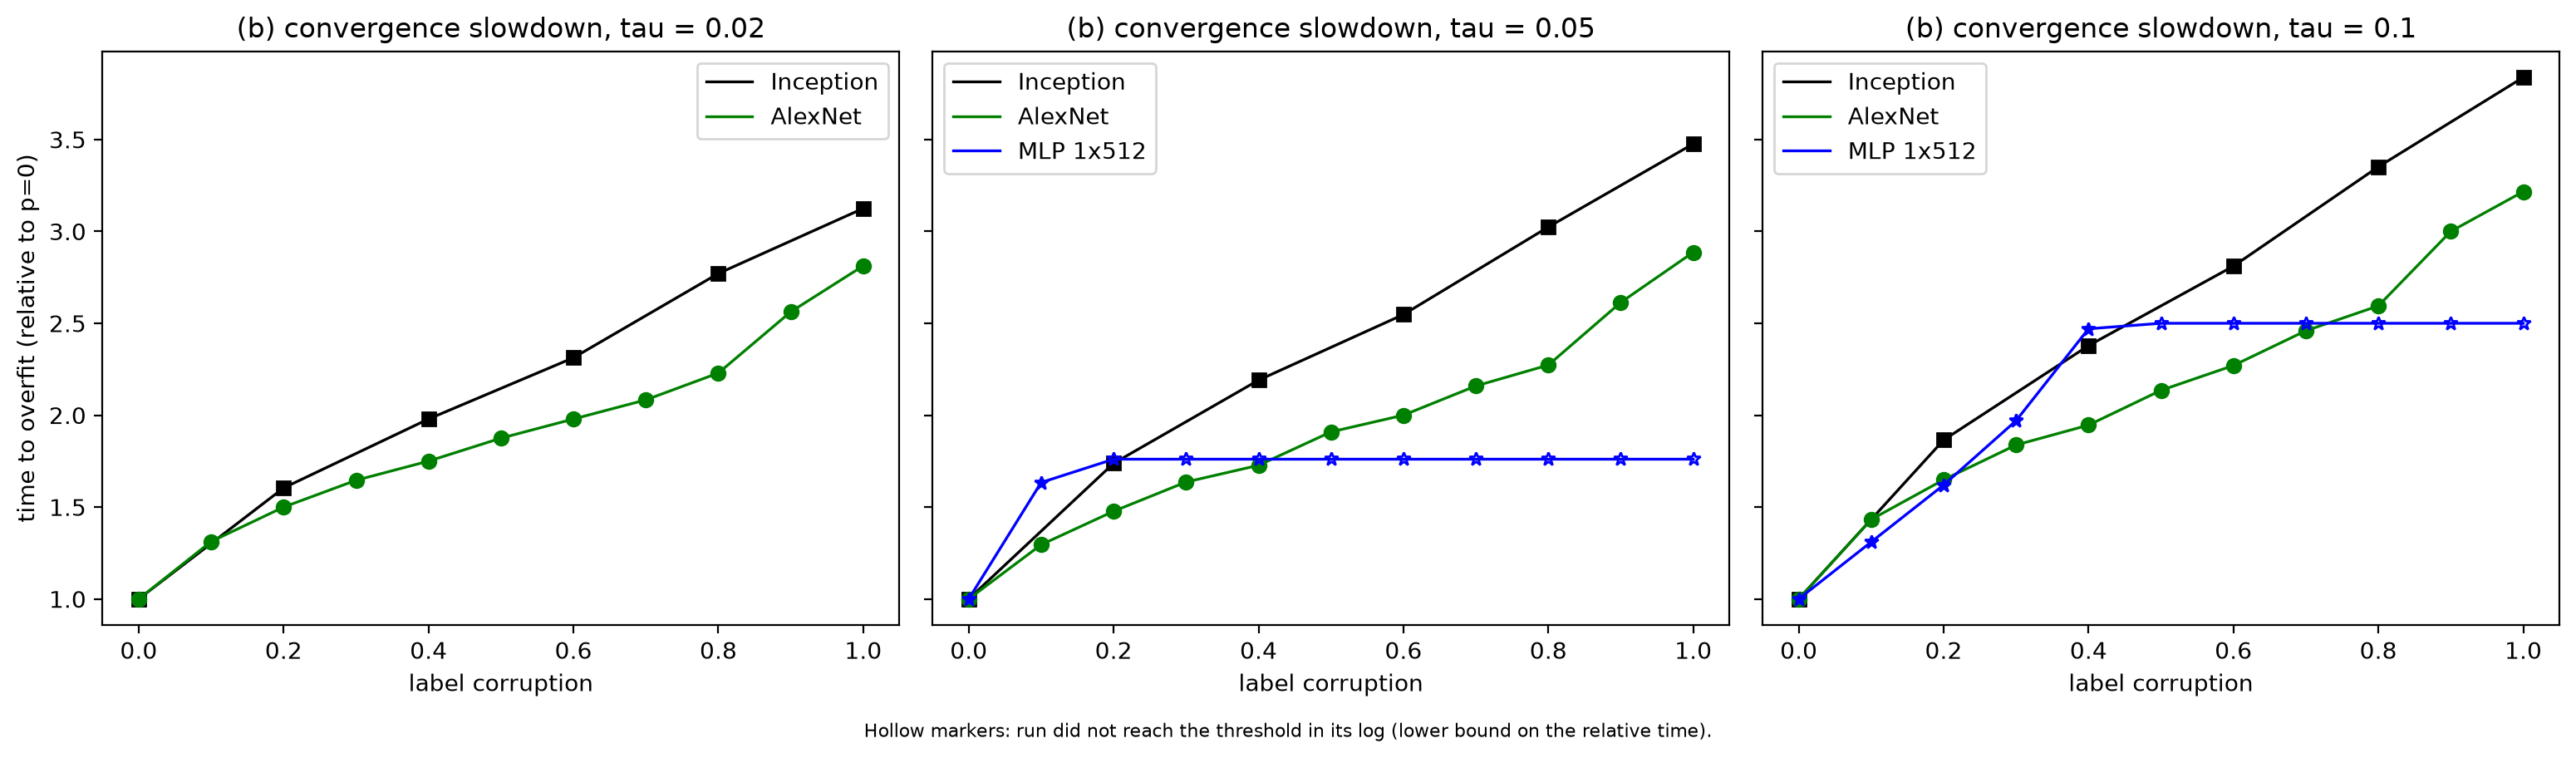

In [5]:
display(Image("phase3_runs/figure1_b_acc_thresholds.png"))
display(Image("phase3_runs/figure1_b_thresholds.png"))

In [6]:
show_csv("phase3_runs/figure1_data.csv")

arch       p    steps_run  cross_step  rel_time            censored_b  test_err  train_err  converged_c  criterion  threshold  early_stopped_log
inception  0.0  25000      4100        1.0                 False       0.1685    0.02502    True         acc        0.98       False            
inception  0.2  8300       7200        1.7560975609756098  False       0.3331    0.01888    True         acc        0.98       True             
inception  0.4  10200      9100        2.2195121951219514  False       0.4613    0.0041     True         acc        0.98       True             
inception  0.6  11700      10600       2.5853658536585367  False       0.648     0.00548    True         acc        0.98       True             
inception  0.8  13700      12600       3.073170731707317   False       0.7953    0.00674    True         acc        0.98       True             
inception  1.0  25000      14200       3.4634146341463414  False       0.8967    0.00708    True         acc        0.98       Fal